# Investigating the Bias–Variance Trade-off in Polynomial Regression

## Research Objective

To investigate how model complexity, training dataset size, observation noise,
and regularisation influence the generalisation performance of regression models.

## Research Questions

1. How does model complexity influence generalisation?
2. How does training dataset size affect bias and variance?
3. How do different noise distributions affect model performance?
4. How does regularisation influence the bias–variance trade-off?
5. How do these relationships change across different model complexities?

## Experiment 1: Effect of Polynomial Degree and Training Dataset Size

In [10]:
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from numpy.polynomial import Chebyshev
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge

noise_std = 0.2
training_sizes = [10,20,50,100,250,500]
degrees = [3,5,10,15]
n_repetitions=30
X_eval=np.linspace(0,1,2000)
y_eval_true=np.sin(1.5*np.pi*X_eval)
datasets = []
rng = np.random.default_rng(42)
models={}
results={}
for repetition in range(n_repetitions):
 for n in training_sizes:
    X = rng.uniform(0, 1, n)
    y_true = np.sin(1.5 * np.pi * X)
    noise = rng.normal(0, noise_std, X.shape)
    y = y_true + noise
    for d in degrees:
     model = Chebyshev.fit(
     X,
     y,
     deg=d,
     domain=[0, 1]
     )
     models[(d, n, repetition)] = model

     predictions = model(X_eval)

     mse = mean_squared_error(y_eval_true, predictions)

     results[(d, n, repetition)] = mse

C:\Users\rajpu\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)
C:\Users\rajpu\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)
C:\Users\rajpu\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)
C:\Users\rajpu\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditioned
  return pu._fit(chebvander, x, y, deg, rcond, full, w)
C:\Users\rajpu\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\polynomial\chebyshev.py:1624: RankWarning: The fit may be poorly conditio

In [2]:
mean_results = {}
std_results = {}

for degree in degrees:
    for size in training_sizes:

        mse_values = []

        for repetition in range(n_repetitions):
            mse_values.append(results[(degree, size, repetition)])

        mean_results[(degree, size)] = np.mean(mse_values)
        std_results[(degree, size)] = np.std(mse_values)

In [3]:
for degree in degrees:
    for size in training_sizes:
        print(
            f"Degree: {degree}, "
            f"Samples: {size}, "
            f"Mean MSE: {mean_results[(degree, size)]:.5f}, "
            f"Std: {std_results[(degree, size)]:.5f}"
        )

Degree: 3, Samples: 10, Mean MSE: 0.13013, Std: 0.31545
Degree: 3, Samples: 20, Mean MSE: 0.01697, Std: 0.01073
Degree: 3, Samples: 50, Mean MSE: 0.00673, Std: 0.00266
Degree: 3, Samples: 100, Mean MSE: 0.00449, Std: 0.00084
Degree: 3, Samples: 250, Mean MSE: 0.00360, Std: 0.00055
Degree: 3, Samples: 500, Mean MSE: 0.00356, Std: 0.00036
Degree: 5, Samples: 10, Mean MSE: 19.22056, Std: 76.64138
Degree: 5, Samples: 20, Mean MSE: 0.07903, Std: 0.12738
Degree: 5, Samples: 50, Mean MSE: 0.00553, Std: 0.00343
Degree: 5, Samples: 100, Mean MSE: 0.00227, Std: 0.00144
Degree: 5, Samples: 250, Mean MSE: 0.00103, Std: 0.00071
Degree: 5, Samples: 500, Mean MSE: 0.00065, Std: 0.00033
Degree: 10, Samples: 10, Mean MSE: 11914870695948.07422, Std: 62733235061591.85938
Degree: 10, Samples: 20, Mean MSE: 1107.95156, Std: 4272.91927
Degree: 10, Samples: 50, Mean MSE: 0.09169, Std: 0.37371
Degree: 10, Samples: 100, Mean MSE: 0.00721, Std: 0.00906
Degree: 10, Samples: 250, Mean MSE: 0.00200, Std: 0.00085
D

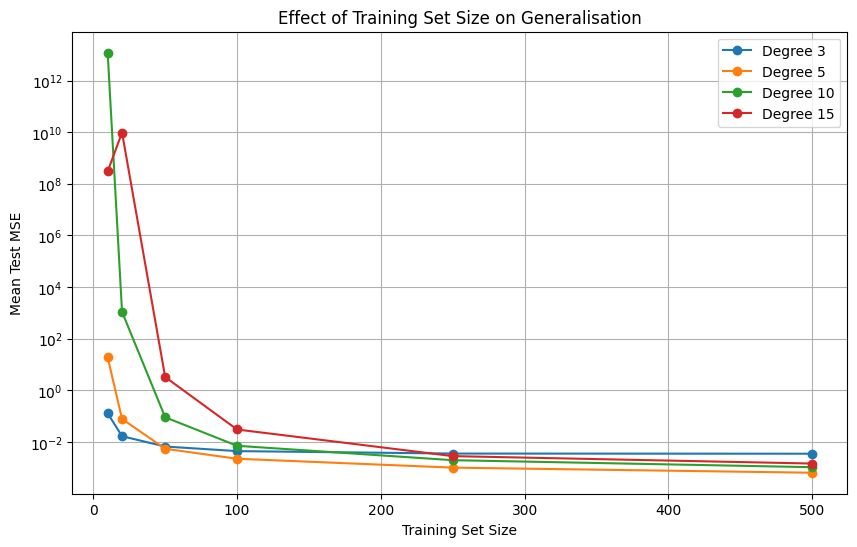

In [4]:
plt.figure(figsize=(10, 6))

for degree in degrees:
    mean_mses = [
        mean_results[(degree, size)]
        for size in training_sizes
    ]

    plt.plot(
        training_sizes,
        mean_mses,
        marker='o',
        label=f'Degree {degree}'
    )

plt.xlabel("Training Set Size")
plt.ylabel("Mean Test MSE")
plt.title("Effect of Training Set Size on Generalisation")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()

## Experiment 2: Bias–Variance Analysis

In [6]:
bias_results = {}
variance_results = {}

for degree in degrees:
    for size in training_sizes:

        predictions_all = []

        for repetition in range(n_repetitions):
            model = models[(degree, size, repetition)]
            predictions_all.append(model(X_eval))

        predictions_all = np.array(predictions_all).squeeze()

        mean_prediction = np.mean(predictions_all, axis=0)

        bias_squared = np.mean(
            (mean_prediction - y_eval_true.ravel()) ** 2
        )

        variance = np.mean(
            np.var(predictions_all, axis=0)
        )

        # Save results
        bias_results[(degree, size)] = bias_squared
        variance_results[(degree, size)] = variance

        # Verification
        mse_direct = np.mean(
            (predictions_all - y_eval_true.ravel()) ** 2
        )

        print(f"Degree: {degree}, Samples: {size}")
        print("Direct MSE:", mse_direct)
        print("Bias squared:", bias_squared)
        print("Variance:", variance)
        print("Bias² + Variance:", bias_squared + variance)
        print("-" * 40)

Degree: 3, Samples: 10
Direct MSE: 0.13012651348009258
Bias squared: 0.005384867292384969
Variance: 0.1247416461877076
Bias² + Variance: 0.13012651348009258
----------------------------------------
Degree: 3, Samples: 20
Direct MSE: 0.01697196615230954
Bias squared: 0.0035507038113814617
Variance: 0.01342126234092808
Bias² + Variance: 0.01697196615230954
----------------------------------------
Degree: 3, Samples: 50
Direct MSE: 0.006733730031139739
Bias squared: 0.003240608625965077
Variance: 0.003493121405174662
Bias² + Variance: 0.006733730031139739
----------------------------------------
Degree: 3, Samples: 100
Direct MSE: 0.004485572576673644
Bias squared: 0.0030768261892031696
Variance: 0.0014087463874704741
Bias² + Variance: 0.004485572576673644
----------------------------------------
Degree: 3, Samples: 250
Direct MSE: 0.003603821970337557
Bias squared: 0.0030575537830268436
Variance: 0.0005462681873107132
Bias² + Variance: 0.003603821970337557
-------------------------------

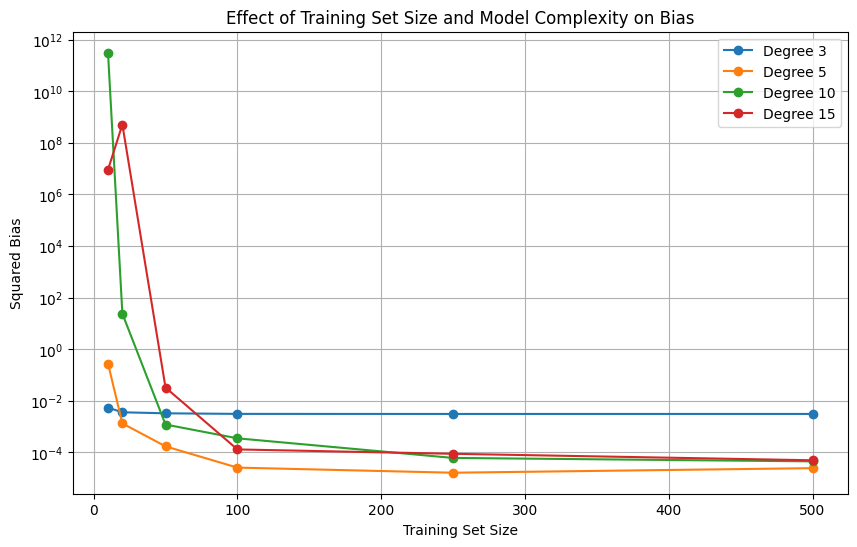

In [7]:
plt.figure(figsize=(10, 6))

for degree in degrees:
    values = [
        bias_results[(degree, size)]
        for size in training_sizes
    ]

    plt.plot(
        training_sizes,
        values,
        marker='o',
        label=f'Degree {degree}'
    )

plt.xlabel("Training Set Size")
plt.ylabel("Squared Bias")
plt.title("Effect of Training Set Size and Model Complexity on Bias")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()

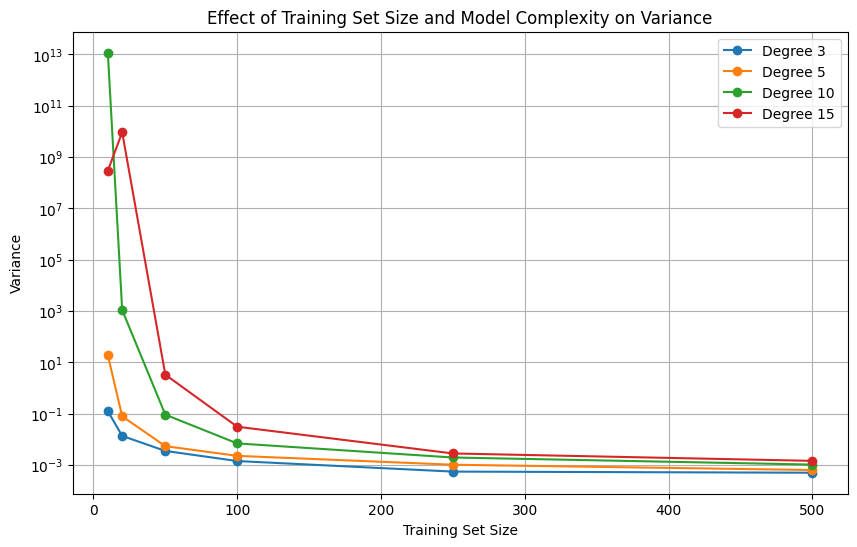

In [8]:
plt.figure(figsize=(10, 6))

for degree in degrees:
    values = [
        variance_results[(degree, size)]
        for size in training_sizes
    ]

    plt.plot(
        training_sizes,
        values,
        marker='o',
        label=f'Degree {degree}'
    )

plt.xlabel("Training Set Size")
plt.ylabel("Variance")
plt.title("Effect of Training Set Size and Model Complexity on Variance")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()

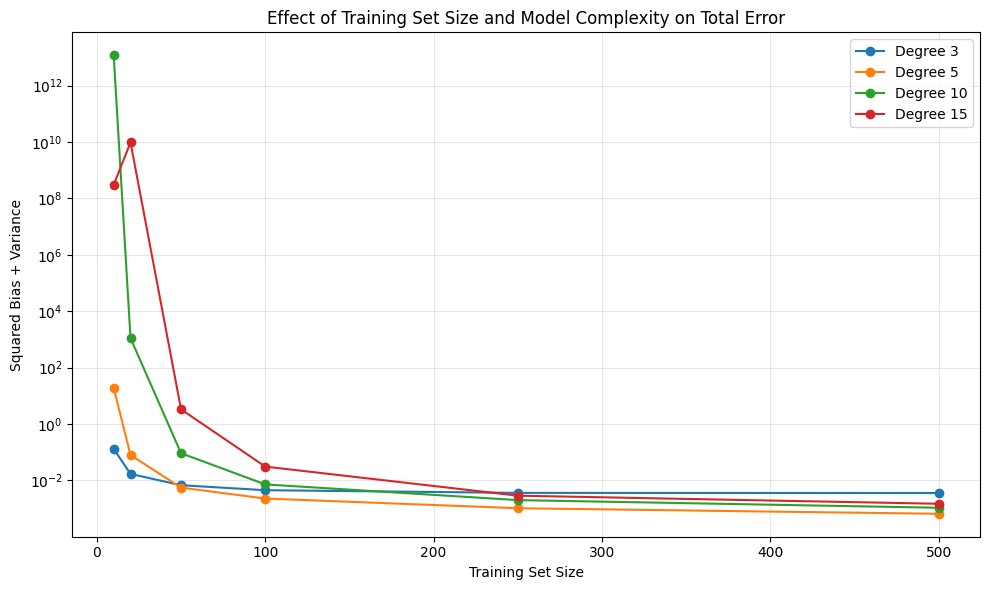

In [9]:
total_error_results = {}

for degree in degrees:
    for size in training_sizes:
        total_error_results[(degree, size)] = (
            bias_results[(degree, size)] +
            variance_results[(degree, size)]
        )

# Plot total error for each polynomial degree
plt.figure(figsize=(10, 6))

for degree in degrees:
    total_errors = [
        total_error_results[(degree, size)]
        for size in training_sizes
    ]

    plt.plot(
        training_sizes,
        total_errors,
        marker='o',
        label=f'Degree {degree}'
    )

plt.yscale('log')

plt.xlabel('Training Set Size')
plt.ylabel('Squared Bias + Variance')
plt.title('Effect of Training Set Size and Model Complexity on Total Error')

plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()

plt.savefig('total_bias_variance.png', dpi=300, bbox_inches='tight')
plt.show()

## Experiment 3: Effect of L2 Regularisation on High-Degree Polynomial Regression

In [12]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error

In [13]:
noise_std = 0.2
degree = 15
n_samples = 50
n_repetitions = 30

lambdas = [0, 0.0001, 0.001, 0.01, 0.1, 1, 10]

X_eval = np.linspace(0, 1, 2000).reshape(-1, 1)
y_eval_true = np.sin(1.5 * np.pi * X_eval.ravel())

rng = np.random.default_rng(42)

results_reg = {}
predictions_reg = {}

for repetition in range(n_repetitions):

    X = rng.uniform(0, 1, n_samples).reshape(-1, 1)

    y_true = np.sin(1.5 * np.pi * X.ravel())
    noise = rng.normal(0, noise_std, n_samples)
    y = y_true + noise

    for lam in lambdas:

        if lam == 0:
            model = make_pipeline(
                PolynomialFeatures(degree=degree, include_bias=False),
                StandardScaler(),
                LinearRegression()
            )
        else:
            model = make_pipeline(
                PolynomialFeatures(degree=degree, include_bias=False),
                StandardScaler(),
                Ridge(alpha=lam, fit_intercept=True)
            )

        model.fit(X, y)

        predictions = model.predict(X_eval)

        mse = mean_squared_error(y_eval_true, predictions)

        results_reg[(lam, repetition)] = mse
        predictions_reg[(lam, repetition)] = predictions

In [14]:
mean_mse_reg = {}
std_mse_reg = {}

for lam in lambdas:

    mse_values = []

    for repetition in range(n_repetitions):
        mse_values.append(results_reg[(lam, repetition)])

    mean_mse_reg[lam] = np.mean(mse_values)
    std_mse_reg[lam] = np.std(mse_values)

    print(
        f"Lambda: {lam:<8} | "
        f"Mean MSE: {mean_mse_reg[lam]:.6f} | "
        f"Std: {std_mse_reg[lam]:.6f}"
    )

Lambda: 0        | Mean MSE: 0.037164 | Std: 0.047325
Lambda: 0.0001   | Mean MSE: 0.008679 | Std: 0.008989
Lambda: 0.001    | Mean MSE: 0.006512 | Std: 0.005815
Lambda: 0.01     | Mean MSE: 0.006086 | Std: 0.005746
Lambda: 0.1      | Mean MSE: 0.007605 | Std: 0.005034
Lambda: 1        | Mean MSE: 0.029943 | Std: 0.006637
Lambda: 10       | Mean MSE: 0.067294 | Std: 0.007586


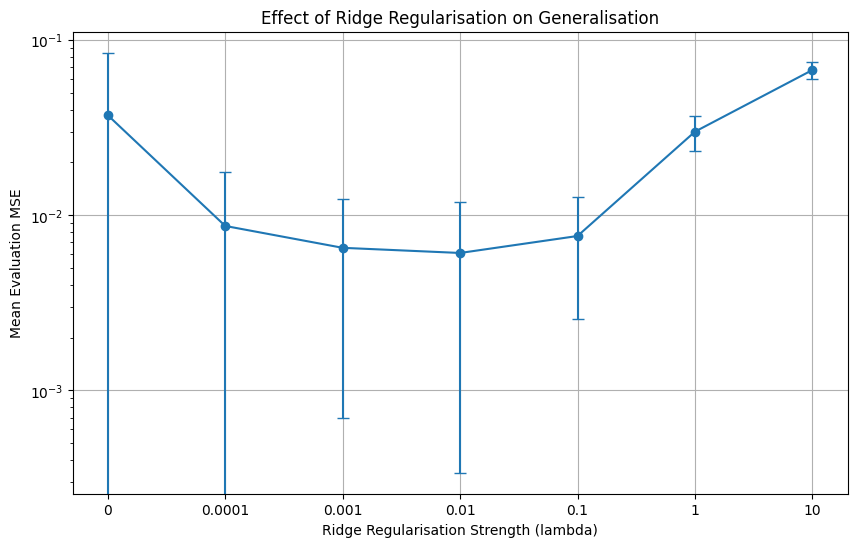

In [15]:
plt.figure(figsize=(10, 6))

plt.errorbar(
    range(len(lambdas)),
    [mean_mse_reg[lam] for lam in lambdas],
    yerr=[std_mse_reg[lam] for lam in lambdas],
    marker='o',
    capsize=4
)

plt.xticks(
    range(len(lambdas)),
    [str(lam) for lam in lambdas]
)

plt.xlabel("Ridge Regularisation Strength (lambda)")
plt.ylabel("Mean Evaluation MSE")
plt.title("Effect of Ridge Regularisation on Generalisation")
plt.yscale("log")
plt.grid(True)

plt.show()

## Experiment 4: Effect of Training Dataset Size on Optimal Regularisation

In [16]:
degree = 15

training_sizes_reg = [10, 50, 100, 500]

lambdas = [0, 0.0001, 0.001, 0.01, 0.1, 1, 10]

n_repetitions = 30
noise_std = 0.2
X_eval = np.linspace(0, 1, 2000).reshape(-1, 1)
y_eval_true = np.sin(1.5 * np.pi * X_eval.ravel())

rng = np.random.default_rng(42)

In [17]:
results_by_size = {}
models_by_size = {}

for size in training_sizes_reg:

    for repetition in range(n_repetitions):

        # Generate one dataset for this repetition
        X = rng.uniform(0, 1, size).reshape(-1, 1)

        y_true = np.sin(1.5 * np.pi * X.ravel())
        noise = rng.normal(0, noise_std, size)
        y = y_true + noise

        # Compare all lambdas on the SAME dataset
        for lam in lambdas:

            if lam == 0:
                model = make_pipeline(
                    PolynomialFeatures(
                        degree=degree,
                        include_bias=False
                    ),
                    StandardScaler(),
                    LinearRegression()
                )
            else:
                model = make_pipeline(
                    PolynomialFeatures(
                        degree=degree,
                        include_bias=False
                    ),
                    StandardScaler(),
                    Ridge(alpha=size*lam)
                )

            model.fit(X, y)

            predictions = model.predict(X_eval)

            mse = mean_squared_error(
                y_eval_true,
                predictions
            )

            key = (size, lam, repetition)

            results_by_size[key] = mse
            models_by_size[key] = model

In [18]:
mean_mse_by_size={}
std_mse_by_size={}

for size in training_sizes_reg:

    for lam in lambdas:
        mean_values=[]
        for n in range(n_repetitions):
            mean_values.append(results_by_size[(size,lam,n)])
        mean_mse_by_size[(size,lam)]=np.mean(mean_values)
        std_mse_by_size[(size,lam)]=np.std(mean_values)
        print(
            f"Samples: {size:3d} | "
            f"Lambda: {lam:<8} | "
            f"Mean MSE: {mean_mse_by_size[(size, lam)]:.6f} | "
            f"Std: {std_mse_by_size[(size, lam)]:.6f}"
        )

Samples:  10 | Lambda: 0        | Mean MSE: 380038559.299939 | Std: 1362697766.285012
Samples:  10 | Lambda: 0.0001   | Mean MSE: 7145.178729 | Std: 32899.037757
Samples:  10 | Lambda: 0.001    | Mean MSE: 1811.356951 | Std: 9167.884480
Samples:  10 | Lambda: 0.01     | Mean MSE: 214.404424 | Std: 1117.790833
Samples:  10 | Lambda: 0.1      | Mean MSE: 26.754850 | Std: 92.729772
Samples:  10 | Lambda: 1        | Mean MSE: 67.501496 | Std: 244.209207
Samples:  10 | Lambda: 10       | Mean MSE: 17.691844 | Std: 72.946061
Samples:  50 | Lambda: 0        | Mean MSE: 0.047046 | Std: 0.083682
Samples:  50 | Lambda: 0.0001   | Mean MSE: 0.007632 | Std: 0.009260
Samples:  50 | Lambda: 0.001    | Mean MSE: 0.007869 | Std: 0.008337
Samples:  50 | Lambda: 0.01     | Mean MSE: 0.020141 | Std: 0.006597
Samples:  50 | Lambda: 0.1      | Mean MSE: 0.055564 | Std: 0.008631
Samples:  50 | Lambda: 1        | Mean MSE: 0.103644 | Std: 0.013960
Samples:  50 | Lambda: 10       | Mean MSE: 0.200032 | Std: 0

In [19]:
for size in training_sizes_reg:

    best_lambda = min(
        lambdas,
        key=lambda lam:mean_mse_by_size[(size,lam)]
    )
    best_mse = mean_mse_by_size[(size, best_lambda)]
    print(
        f"Samples: {size:3d} | "
        f"Best lambda: {best_lambda} | "
        f"Mean MSE: {best_mse:.6f}"
    )

Samples:  10 | Best lambda: 10 | Mean MSE: 17.691844
Samples:  50 | Best lambda: 0.0001 | Mean MSE: 0.007632
Samples: 100 | Best lambda: 0.0001 | Mean MSE: 0.002828
Samples: 500 | Best lambda: 0.0001 | Mean MSE: 0.000598


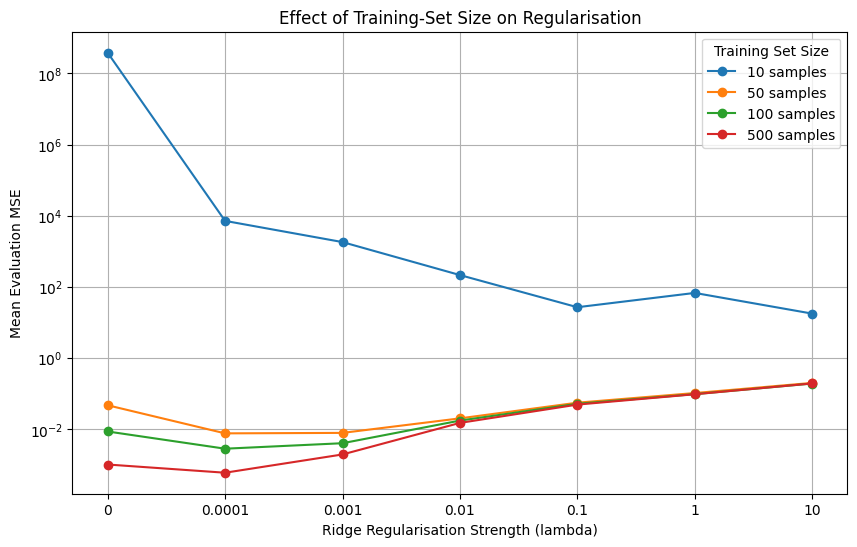

In [20]:
plt.figure(figsize=(10, 6))

for size in training_sizes_reg:

    mean_mses = [
        mean_mse_by_size[(size, lam)]
        for lam in lambdas
    ]

    plt.plot(
        range(len(lambdas)),
        mean_mses,
        marker='o',
        label=f'{size} samples'
    )

plt.xticks(
    range(len(lambdas)),
    [str(lam) for lam in lambdas]
)

plt.xlabel("Ridge Regularisation Strength (lambda)")
plt.ylabel("Mean Evaluation MSE")
plt.title("Effect of Training-Set Size on Regularisation")
plt.yscale("log")
plt.legend(title="Training Set Size")
plt.grid(True)

plt.show()

## Experiment 5: Effect of Polynomial Degree on Regularisation Performance

In [21]:
degrees = [3, 5, 10, 15]
training_sizes_reg = [50, 100]
lambdas = [0, 0.0001, 0.001, 0.01, 0.1, 1, 10]

n_repetitions = 30
noise_std = 0.2

In [22]:
results_complexity={}
rng = np.random.default_rng(42)
for degree in degrees:
    for size in training_sizes_reg:
        for repetition in range(n_repetitions):
            X = rng.uniform(0,1,size).reshape(-1,1)
            y_true = np.sin(1.5*np.pi*X.ravel())
            noise = rng.normal(0,noise_std,size)
            y = y_true + noise

            for lam in lambdas:
                if lam==0:
                    model = make_pipeline(
                        PolynomialFeatures(degree=degree,include_bias=False),
                        StandardScaler(),
                        LinearRegression()
                    )
                else:
                   model = make_pipeline(
                        PolynomialFeatures(degree=degree,include_bias=False),
                        StandardScaler(),
                        Ridge(alpha=lam)
                    )
                model.fit(X,y)
                predictions = model.predict(X_eval)
                mse = mean_squared_error(
                  y_eval_true,
                  predictions
              )
                results_complexity[
                  (degree,size,lam,repetition)
                ] = mse
            

In [23]:
mean_mse_complexity = {}
std_mse_complexity = {}

for degree in degrees:
    for size in training_sizes_reg:
        for lam in lambdas:

            mse_values = [
                results_complexity[
                    (degree, size, lam, repetition)
                ]
                for repetition in range(n_repetitions)
            ]
            mean_mse_complexity[(degree,size,lam)]=np.mean(mse_values)
            std_mse_complexity[(degree,size,lam)]=np.std(mse_values)

In [24]:
for degree in degrees:
    for size in training_sizes_reg:

        best_lambda = min(
            lambdas,
            key=lambda lam: mean_mse_complexity[
                (degree, size, lam)
            ]
        )

        best_mse = mean_mse_complexity[
            (degree, size, best_lambda)
        ]

        print(
            f"Degree: {degree:2d} | "
            f"Samples: {size:3d} | "
            f"Best lambda: {best_lambda:<8} | "
            f"Mean MSE: {best_mse:.6f}"
        )

Degree:  3 | Samples:  50 | Best lambda: 0.001    | Mean MSE: 0.006186
Degree:  3 | Samples: 100 | Best lambda: 0.001    | Mean MSE: 0.004750
Degree:  5 | Samples:  50 | Best lambda: 0.01     | Mean MSE: 0.005546
Degree:  5 | Samples: 100 | Best lambda: 0.0001   | Mean MSE: 0.002619
Degree: 10 | Samples:  50 | Best lambda: 0.01     | Mean MSE: 0.005566
Degree: 10 | Samples: 100 | Best lambda: 0.01     | Mean MSE: 0.002139
Degree: 15 | Samples:  50 | Best lambda: 0.1      | Mean MSE: 0.016333
Degree: 15 | Samples: 100 | Best lambda: 0.01     | Mean MSE: 0.002615


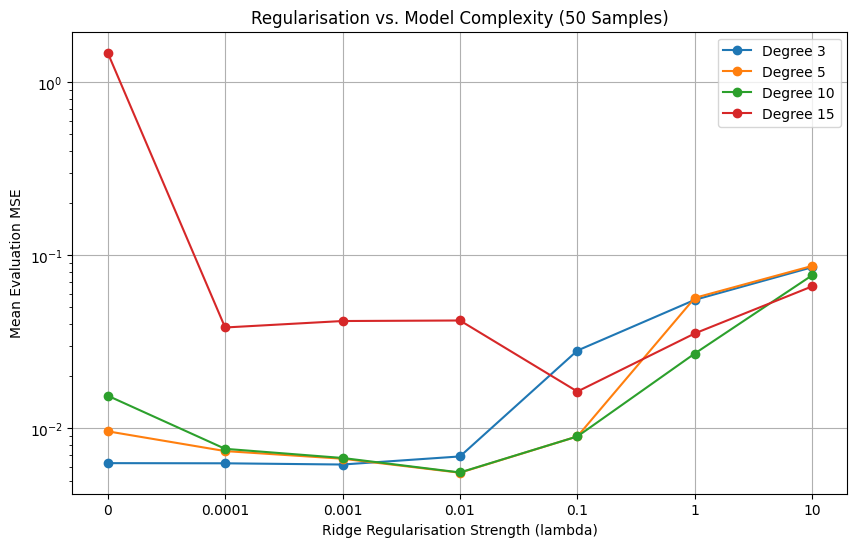

In [25]:
plt.figure(figsize=(10, 6))

for degree in degrees:

    mean_mses = [
        mean_mse_complexity[(degree, 50, lam)]
        for lam in lambdas
    ]

    plt.plot(
        range(len(lambdas)),
        mean_mses,
        marker='o',
        label=f'Degree {degree}'
    )

plt.xticks(
    range(len(lambdas)),
    [str(lam) for lam in lambdas]
)

plt.xlabel("Ridge Regularisation Strength (lambda)")
plt.ylabel("Mean Evaluation MSE")
plt.title("Regularisation vs. Model Complexity (50 Samples)")
plt.yscale("log")
plt.legend()
plt.grid(True)

plt.show()

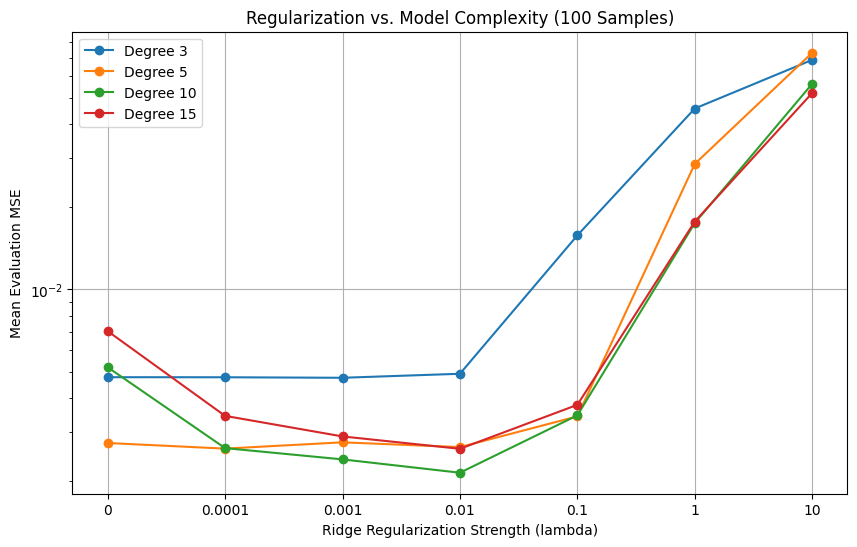

In [26]:
plt.figure(figsize=(10, 6))

for degree in degrees:

    mean_mses = [
        mean_mse_complexity[(degree, 100, lam)]
        for lam in lambdas
    ]

    plt.plot(
        range(len(lambdas)),
        mean_mses,
        marker='o',
        label=f'Degree {degree}'
    )

plt.xticks(
    range(len(lambdas)),
    [str(lam) for lam in lambdas]
)

plt.xlabel("Ridge Regularization Strength (lambda)")
plt.ylabel("Mean Evaluation MSE")
plt.title("Regularization vs. Model Complexity (100 Samples)")
plt.yscale("log")
plt.legend()
plt.grid(True)

plt.show()

## Experiment 6: Effect of Observation Noise on Optimal Regularisation

In [27]:
noise_levels = [0.05, 0.1, 0.2, 0.4, 0.6]

degree = 15
n_samples = 50
n_repetitions = 100

lambdas = [0, 0.0001, 0.001, 0.01, 0.1, 1, 10]

X_eval = np.linspace(0, 1, 2000).reshape(-1, 1)
y_eval_true = np.sin(1.5 * np.pi * X_eval.ravel())

In [28]:
results_noise = {}
rng = np.random.default_rng(42)
for n in noise_levels:

    for r in range(n_repetitions):
        X_train = rng.uniform(0,1,(n_samples,1))
        y_true = np.sin(1.5*np.pi*X_train.ravel())
        noise = rng.normal(0,n, n_samples)
        y_train = y_true + noise

        for lam in lambdas:
            if lam == 0:
                model = make_pipeline(
                    PolynomialFeatures(degree=degree, include_bias = False),
                    StandardScaler(),
                    LinearRegression()
                )
            else:
                model = make_pipeline(
                    PolynomialFeatures(degree=degree, include_bias = False),
                    StandardScaler(),
                    Ridge(alpha=lam)
                )

            model.fit(X_train, y_train)

            train_predictions = model.predict(X_train)
            eval_predictions = model.predict(X_eval)

            results_noise[(n, lam, r)] = {
                "train_noisy": mean_squared_error(
                    y_train, train_predictions
                ),
                "train_clean": mean_squared_error(
                    y_true, train_predictions
                ),
                "eval": mean_squared_error(
                    y_eval_true, eval_predictions
                )
            }

In [29]:
mean_eval_noise = {}

for noise_std in noise_levels:

    for lam in lambdas:

        errors = [
            results_noise[(noise_std, lam, r)]["eval"]
            for r in range(n_repetitions)
        ]

        mean_eval_noise[(noise_std, lam)] = np.mean(errors)

In [30]:
print(f"{'Noise':<10}", end="")

for lam in lambdas:
    print(f"{lam:<12}", end="")

print()

for noise_std in noise_levels:

    print(f"{noise_std:<10}", end="")

    for lam in lambdas:
        value = mean_eval_noise[(noise_std, lam)]
        print(f"{value:<12.6f}", end="")

    print()

Noise     0           0.0001      0.001       0.01        0.1         1           10          
0.05      0.005127    0.001039    0.000617    0.000800    0.003936    0.028449    0.065677    
0.1       0.601784    0.009524    0.004883    0.004551    0.007430    0.031765    0.064633    
0.2       0.263388    0.023117    0.012349    0.009302    0.010071    0.035424    0.067025    
0.4       1.503725    0.168465    0.102332    0.059941    0.035199    0.045973    0.077400    
0.6       0.850238    0.134579    0.092911    0.074256    0.055129    0.066621    0.093204    


In [31]:
best_lambdas = []
best_errors = []

for noise_std in noise_levels:

    errors = [
        mean_eval_noise[(noise_std, lam)]
        for lam in lambdas
    ]

    best_idx = np.argmin(errors)

    best_lambdas.append(lambdas[best_idx])
    best_errors.append(errors[best_idx])

print("Noise levels:", noise_levels)
print("Optimal lambdas:", best_lambdas)

Noise levels: [0.05, 0.1, 0.2, 0.4, 0.6]
Optimal lambdas: [0.001, 0.01, 0.01, 0.1, 0.1]


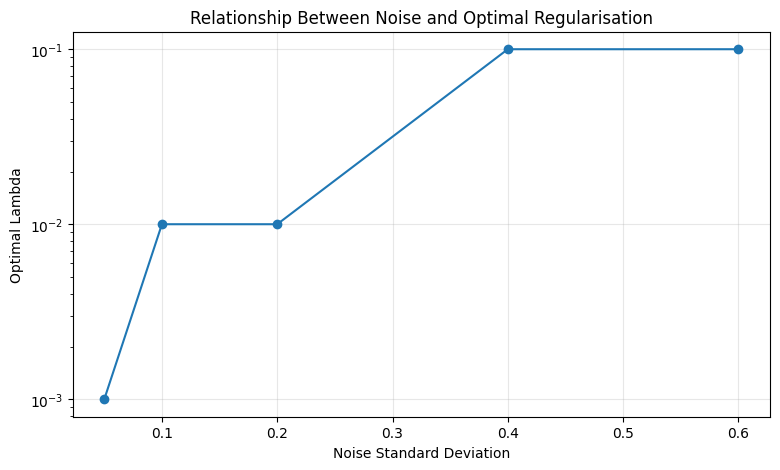

In [32]:
plt.figure(figsize=(9, 5))

plt.plot(noise_levels, best_lambdas, marker='o')

plt.xlabel("Noise Standard Deviation")
plt.ylabel("Optimal Lambda")
plt.title("Relationship Between Noise and Optimal Regularisation")

plt.yscale('log')
plt.grid(True, alpha=0.3)

plt.show()

## Eperiment 7: Interaction Between Polynomial Degree, Noise, and Regularisation

In [33]:
degrees = [3, 5, 10, 15]

n_samples = 50
noise_std = 0.2

n_repetitions = 100

lambdas = [0, 0.0001, 0.001, 0.01, 0.1, 1, 10]

X_eval = np.linspace(0, 1, 2000).reshape(-1, 1)
y_eval_true = np.sin(1.5 * np.pi * X_eval.ravel())

In [34]:
results_degree = {}

rng = np.random.default_rng(42)

for r in range(n_repetitions):

    # Generate one training dataset
    X_train = rng.uniform(0, 1, (n_samples, 1))

    y_true = np.sin(1.5 * np.pi * X_train.ravel())

    noise = rng.normal(0, noise_std, n_samples)
    y_train = y_true + noise

    # Compare different polynomial degrees
    for deg in degrees:

        for lam in lambdas:

            if lam == 0:
                model = make_pipeline(
                    PolynomialFeatures(degree=deg, include_bias=False),
                    StandardScaler(),
                    LinearRegression()
                )
            else:
                model = make_pipeline(
                    PolynomialFeatures(degree=deg, include_bias=False),
                    StandardScaler(),
                    Ridge(alpha=lam)
                )

            model.fit(X_train, y_train)

            train_predictions = model.predict(X_train)
            eval_predictions = model.predict(X_eval)

            results_degree[(deg, lam, r)] = {
                "train_noisy": mean_squared_error(
                    y_train, train_predictions
                ),
                "train_clean": mean_squared_error(
                    y_true, train_predictions
                ),
                "eval": mean_squared_error(
                    y_eval_true, eval_predictions
                )
            }

print("Experiment completed!")

Experiment completed!


In [35]:
mean_eval_degree = {}

for deg in degrees:

    for lam in lambdas:

        errors = [
            results_degree[(deg, lam, r)]["eval"]
            for r in range(n_repetitions)
        ]

        mean_eval_degree[(deg,lam)] = np.mean(errors)

In [36]:
print(f"{'Degree':<12}", end="")

for lam in lambdas:
    print(f"{lam:<12}", end="")

print()

for deg in degrees:

    print(f"{deg:<12}", end="")

    for lam in lambdas:
        value = mean_eval_degree[(deg, lam)]
        print(f"{value:<12.6f}", end="")

    print()

Degree      0           0.0001      0.001       0.01        0.1         1           10          
3           0.007463    0.007454    0.007392    0.008234    0.028867    0.055694    0.085267    
5           0.007091    0.005145    0.004902    0.004375    0.007749    0.048254    0.082687    
10          0.044253    0.006979    0.006154    0.005332    0.009214    0.028344    0.077660    
15          0.082017    0.015091    0.008735    0.006863    0.008441    0.032552    0.068231    
